In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_excel("Seaborn Business Analytics.xlsx", sheet_name="Sales_Data")
df

,Order_ID,Order_Date,Month,Quarter,City,Region,Customer_Segment,Sales_Channel,Product_Category,Units_Sold,...,Cost_Amount,Profit,Marketing_Spend,Customer_Count,Customer_Rating,Delivery_Days,Returned_Units,Payment_Method,Profit_Margin_Pct,Revenue_per_Unit
0,ORD10001,2025-01-01 00:00:00.000,Jan,Q1,Kolkata,East,Corporate,Online,Accessories,7,...,17314.65,7477.36,13169.23,7,2.3,7,0,Credit Card,30.16,3541.72
1,ORD10002,2025-01-02 05:13:02.609,Jan,Q1,Hyderabad,South,Corporate,Marketplace,Electronics,13,...,160856.88,46902.97,15354.70,4,4.1,8,0,UPI,22.58,15981.53
2,ORD10003,2025-01-03 10:26:05.217,Jan,Q1,Delhi,North,Consumer,Retail Store,Electronics,13,...,217996.23,165427.02,1801.21,1,5.0,1,1,UPI,43.14,29494.10
3,ORD10004,2025-01-04 15:39:07.826,Jan,Q1,Kolkata,East,Small Business,Online,Office Supplies,2,...,5383.90,2717.55,9728.63,5,4.7,1,0,Net Banking,33.54,4050.72
4,ORD10005,2025-01-05 20:52:10.435,Jan,Q1,Bengaluru,South,Consumer,Online,Accessories,3,...,5063.47,3784.00,18583.25,2,4.1,3,0,Cash,42.77,2949.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,ORD10296,2025-12-26 03:07:49.565,Dec,Q4,Hyderabad,South,Small Business,Retail Store,Accessories,10,...,9745.58,6638.24,21331.35,3,3.4,7,1,UPI,40.52,1638.38
296,ORD10297,2025-12-27 08:20:52.174,Dec,Q4,Chennai,South,Consumer,Online,Accessories,2,...,3311.98,1316.03,13746.05,5,4.2,8,2,Debit Card,28.44,2314.00
297,ORD10298,2025-12-28 13:33:54.783,Dec,Q4,Kolkata,East,Corporate,Online,Home Appliances,14,...,70070.02,38056.52,21201.36,3,4.4,4,1,UPI,35.20,7723.32
298,ORD10299,2025-12-29 18:46:57.391,Dec,Q4,Delhi,North,Small Business,Marketplace,Furniture,2,...,23270.50,6102.53,14925.32,1,4.3,7,0,Net Banking,20.78,14686.52


In [5]:
print(df.head())
print(df.shape)
print(df.columns)

   Order_ID              Order_Date Month Quarter       City Region  \
0  ORD10001 2025-01-01 00:00:00.000   Jan      Q1    Kolkata   East   
1  ORD10002 2025-01-02 05:13:02.609   Jan      Q1  Hyderabad  South   
2  ORD10003 2025-01-03 10:26:05.217   Jan      Q1      Delhi  North   
3  ORD10004 2025-01-04 15:39:07.826   Jan      Q1    Kolkata   East   
4  ORD10005 2025-01-05 20:52:10.435   Jan      Q1  Bengaluru  South   

  Customer_Segment Sales_Channel Product_Category  Units_Sold  ...  \
0        Corporate        Online      Accessories           7  ...   
1        Corporate   Marketplace      Electronics          13  ...   
2         Consumer  Retail Store      Electronics          13  ...   
3   Small Business        Online  Office Supplies           2  ...   
4         Consumer        Online      Accessories           3  ...   

   Cost_Amount     Profit  Marketing_Spend  Customer_Count  Customer_Rating  \
0     17314.65    7477.36         13169.23               7              2

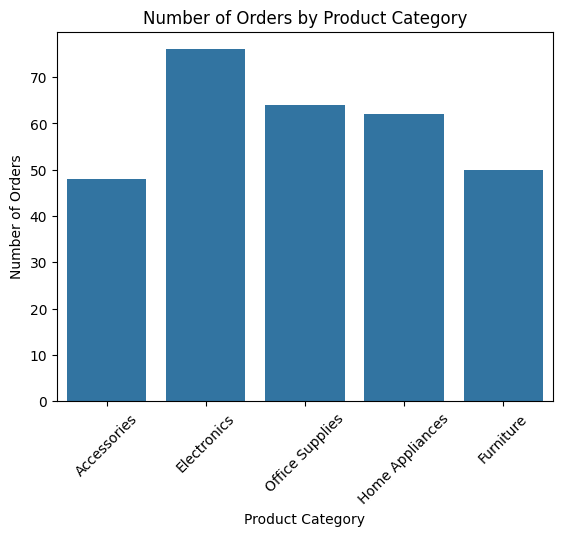

Product_Category
Electronics        76
Office Supplies    64
Home Appliances    62
Furniture          50
Accessories        48
Name: count, dtype: int64
Highest number of orders: Electronics


In [6]:
sns.countplot(data=df, x="Product_Category")
plt.title("Number of Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

print(df["Product_Category"].value_counts())
highest_category = df["Product_Category"].value_counts().idxmax()
print("Highest number of orders:", highest_category)

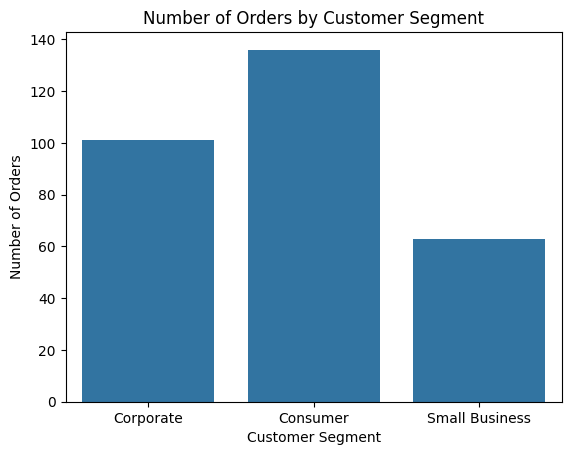

Customer_Segment
Consumer          136
Corporate         101
Small Business     63
Name: count, dtype: int64
Highest order segment: Consumer


In [8]:
sns.countplot(data=df, x="Customer_Segment")
plt.title("Number of Orders by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Orders")
plt.show()
print(df["Customer_Segment"].value_counts())
highest_segment = df["Customer_Segment"].value_counts().idxmax()
print("Highest order segment:", highest_segment)

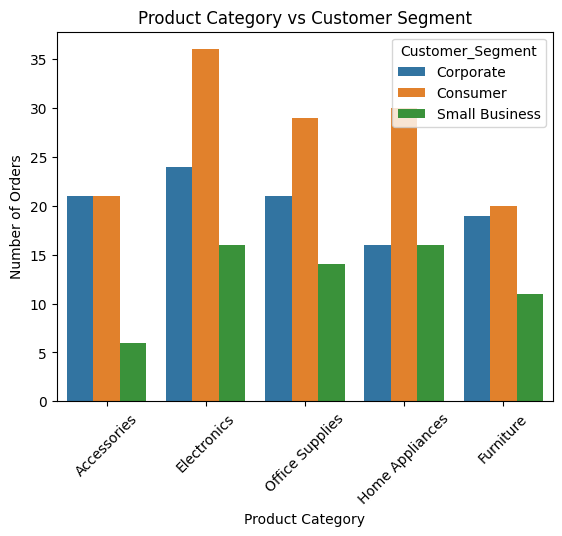

In [9]:
sns.countplot(
    data=df,
    x="Product_Category",
    hue="Customer_Segment"
)

plt.title("Product Category vs Customer Segment")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

In [10]:
category_segment = pd.crosstab(df["Product_Category"],df["Customer_Segment"])

print(category_segment)
print("\nHighest segment in each category:")
print(category_segment.idxmax(axis=1))

Customer_Segment  Consumer  Corporate  Small Business
Product_Category                                     
Accessories             21         21               6
Electronics             36         24              16
Furniture               20         19              11
Home Appliances         30         16              16
Office Supplies         29         21              14

Highest segment in each category:
Product_Category
Accessories        Consumer
Electronics        Consumer
Furniture          Consumer
Home Appliances    Consumer
Office Supplies    Consumer
dtype: object


Product_Category
Accessories         18433.631042
Electronics        234681.778026
Furniture          118315.903800
Home Appliances     90900.773065
Office Supplies     34216.779219
Name: Sales_Amount, dtype: float64


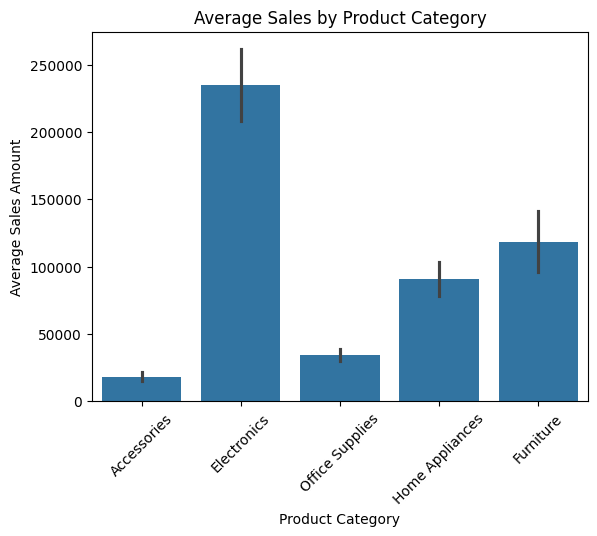

Highest average sales category: Electronics


In [11]:
avg_sales = df.groupby("Product_Category")["Sales_Amount"].mean()
print(avg_sales)

sns.barplot(data=df,x="Product_Category",y="Sales_Amount",estimator="mean")
plt.title("Average Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Sales Amount")
plt.xticks(rotation=45)
plt.show()
print("Highest average sales category:", avg_sales.idxmax())

Region
East     23682.399070
North    40786.296471
South    35225.841652
West     37734.803056
Name: Profit, dtype: float64


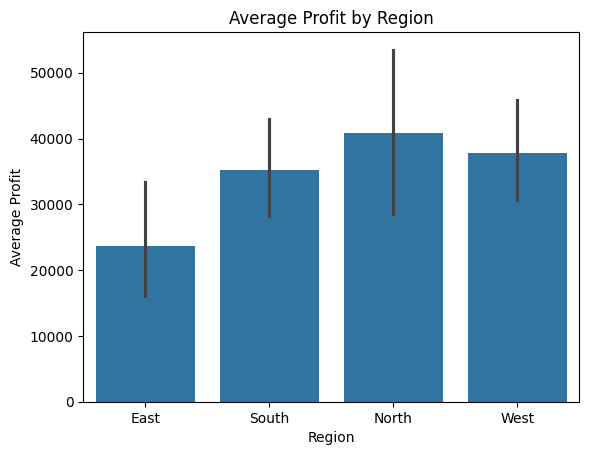

Highest average profit region: North


In [13]:
avg_profit = df.groupby("Region")["Profit"].mean()
print(avg_profit)
sns.barplot(data=df,x="Region",y="Profit",estimator="mean")
plt.title("Average Profit by Region")
plt.xlabel("Region")
plt.ylabel("Average Profit")
plt.show()
print("Highest average profit region:", avg_profit.idxmax())

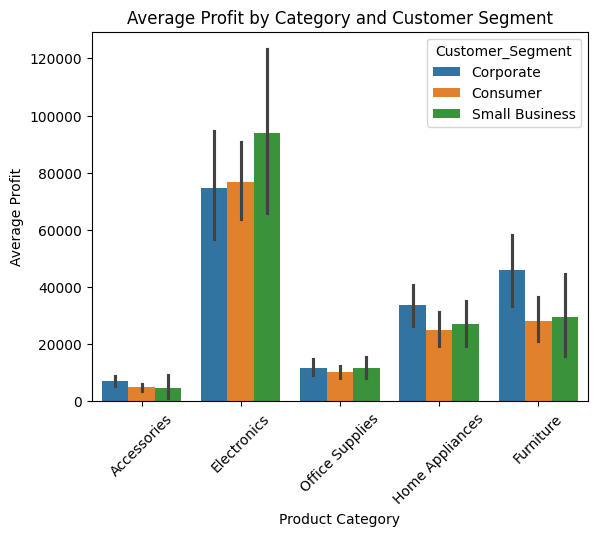

In [15]:
sns.barplot(data=df,x="Product_Category",y="Profit",hue="Customer_Segment",estimator="mean")

plt.title("Average Profit by Category and Customer Segment")
plt.xlabel("Product Category")
plt.ylabel("Average Profit")
plt.xticks(rotation=45)
plt.show()

In [16]:
category_segment_profit = df.pivot_table(values="Profit",index="Product_Category",columns="Customer_Segment",aggfunc="mean")
print(category_segment_profit)
print("\nMost profitable segment in each category:")
print(category_segment_profit.idxmax(axis=1))

Customer_Segment      Consumer     Corporate  Small Business
Product_Category                                            
Accessories        4867.679524   7177.528571     4521.310000
Electronics       76835.681111  74504.341667    93985.025000
Furniture         28198.268000  45981.116842    29669.219091
Home Appliances   24882.289000  33853.342500    26996.220625
Office Supplies   10293.829310  11841.493810    11582.808571

Most profitable segment in each category:
Product_Category
Accessories             Corporate
Electronics        Small Business
Furniture               Corporate
Home Appliances         Corporate
Office Supplies         Corporate
dtype: object


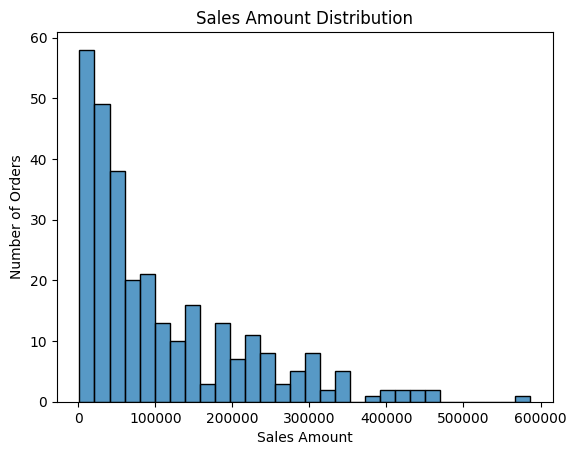

In [17]:
sns.histplot(data=df,x="Sales_Amount",bins=30)

plt.title("Sales Amount Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Orders")
plt.show()

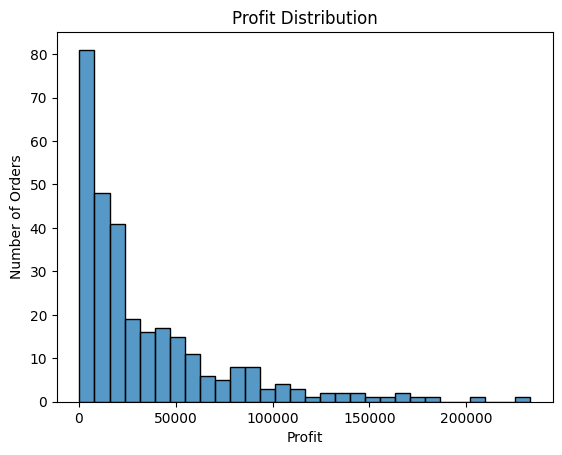

In [18]:
sns.histplot(data=df,x="Profit",bins=30)

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Number of Orders")
plt.show()

In [19]:
print("Average Profit:", df["Profit"].mean())
print("Median Profit:", df["Profit"].median())

Average Profit: 35104.692533333335
Median Profit: 19477.045


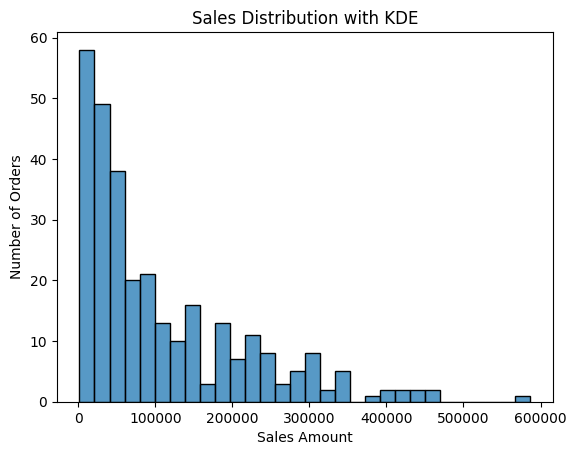

In [20]:
sns.histplot(data=df,x="Sales_Amount",bins=30,)

plt.title("Sales Distribution with KDE")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Orders")
plt.show()

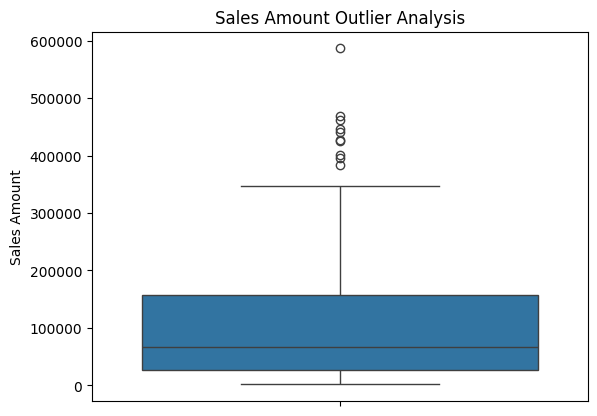

In [21]:
sns.boxplot(data=df,y="Sales_Amount")

plt.title("Sales Amount Outlier Analysis")
plt.ylabel("Sales Amount")
plt.show()

In [22]:
Q1 = df["Sales_Amount"].quantile(0.25)
Q3 = df["Sales_Amount"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
outliers = df[(df["Sales_Amount"] < lower_limit) |(df["Sales_Amount"] > upper_limit)]

print("Number of outliers:", len(outliers))
print(outliers[["Order_ID", "Sales_Amount"]])

Number of outliers: 10
     Order_ID  Sales_Amount
2    ORD10003     383423.25
39   ORD10040     468897.69
59   ORD10060     395945.66
63   ORD10064     427740.03
133  ORD10134     462358.08
168  ORD10169     401272.36
189  ORD10190     425252.32
250  ORD10251     446162.47
289  ORD10290     441577.17
290  ORD10291     586769.83


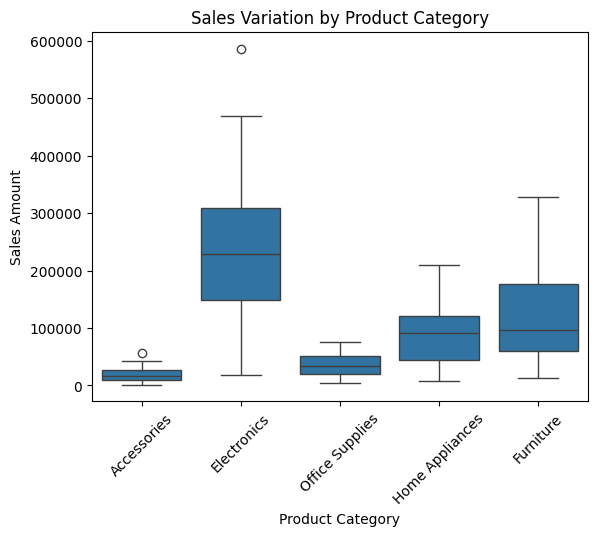

In [23]:
sns.boxplot(data=df,x="Product_Category",y="Sales_Amount")

plt.title("Sales Variation by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.show()

In [24]:
variation = df.groupby("Product_Category")["Sales_Amount"].std()
print(variation)
print("Category with highest variation:",variation.idxmax())

Product_Category
Accessories         12576.831530
Electronics        118994.991622
Furniture           80136.560430
Home Appliances     52663.488856
Office Supplies     19560.024005
Name: Sales_Amount, dtype: float64
Category with highest variation: Electronics


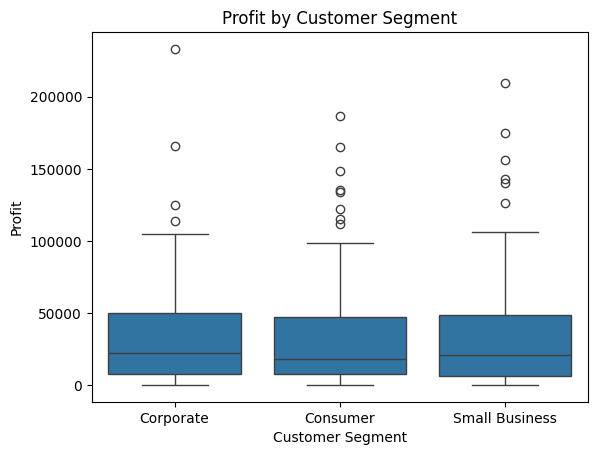

In [25]:
sns.boxplot(data=df,x="Customer_Segment",y="Profit")

plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit")
plt.show()

In [26]:
median_profit = df.groupby("Customer_Segment")["Profit"].median()

print("Median Profit:")
print(median_profit)

print("Highest median profit:",median_profit.idxmax())

Median Profit:
Customer_Segment
Consumer          18106.565
Corporate         22201.960
Small Business    21227.670
Name: Profit, dtype: float64
Highest median profit: Corporate


In [27]:
profit_spread = df.groupby("Customer_Segment")["Profit"].agg(lambda x: x.quantile(0.75) - x.quantile(0.25))

print("\nProfit Spread:")
print(profit_spread)

print("Largest spread:",profit_spread.idxmax())


Profit Spread:
Customer_Segment
Consumer          39505.1675
Corporate         42192.7900
Small Business    42346.9600
Name: Profit, dtype: float64
Largest spread: Small Business


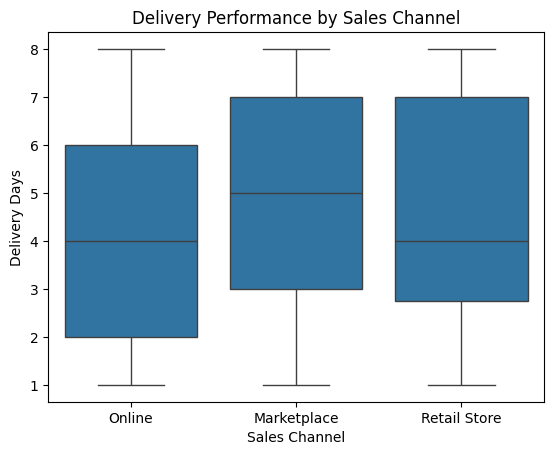

In [28]:
sns.boxplot(data=df,x="Sales_Channel",y="Delivery_Days")

plt.title("Delivery Performance by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Delivery Days")
plt.show()

In [29]:
delivery_variation = df.groupby("Sales_Channel")["Delivery_Days"].std()
print(delivery_variation)
print("Most consistent channel:",delivery_variation.idxmin())

Sales_Channel
Marketplace     2.187210
Online          2.338920
Retail Store    2.384654
Name: Delivery_Days, dtype: float64
Most consistent channel: Marketplace


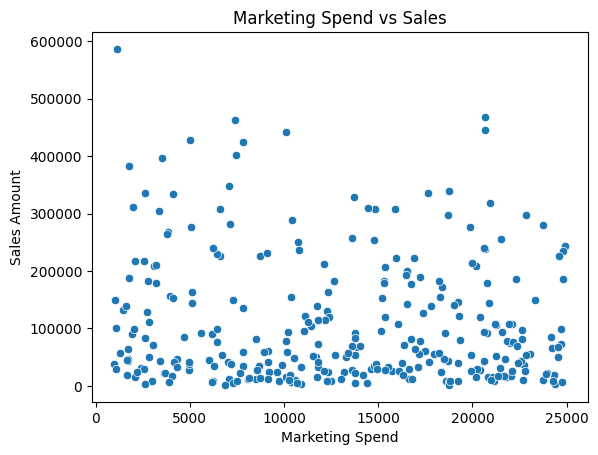

In [30]:
sns.scatterplot(data=df,x="Marketing_Spend",y="Sales_Amount")

plt.title("Marketing Spend vs Sales")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Amount")
plt.show()

In [31]:
correlation = df["Marketing_Spend"].corr(df["Sales_Amount"])

print("Correlation:", round(correlation, 2))

Correlation: -0.1


In [32]:
if correlation > 0.5:
    print("Higher marketing spending is strongly associated with higher sales.")
elif correlation > 0:
    print("There is a positive relationship between marketing spending and sales.")
else:
    print("There is no positive relationship between marketing spending and sales.")

There is no positive relationship between marketing spending and sales.


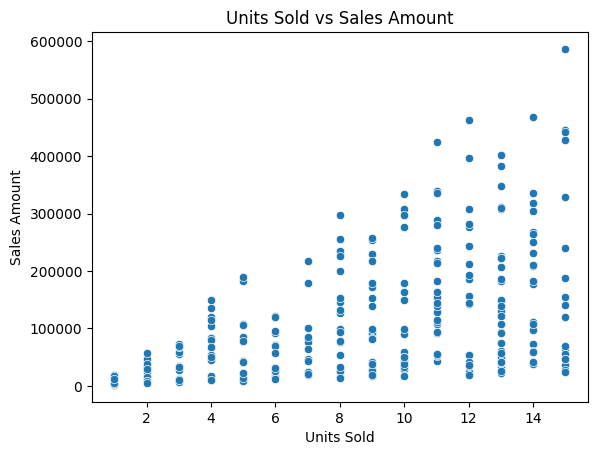

In [33]:
sns.scatterplot(data=df,x="Units_Sold",y="Sales_Amount")

plt.title("Units Sold vs Sales Amount")
plt.xlabel("Units Sold")
plt.ylabel("Sales Amount")
plt.show()

In [34]:
correlation = df["Units_Sold"].corr(df["Sales_Amount"])
print("Correlation:", round(correlation, 2))

Correlation: 0.54


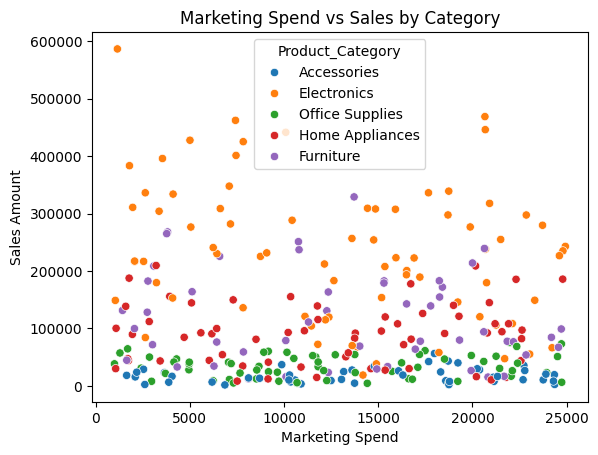

In [35]:
sns.scatterplot(data=df,x="Marketing_Spend",y="Sales_Amount",hue="Product_Category")

plt.title("Marketing Spend vs Sales by Category")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Amount")
plt.show()

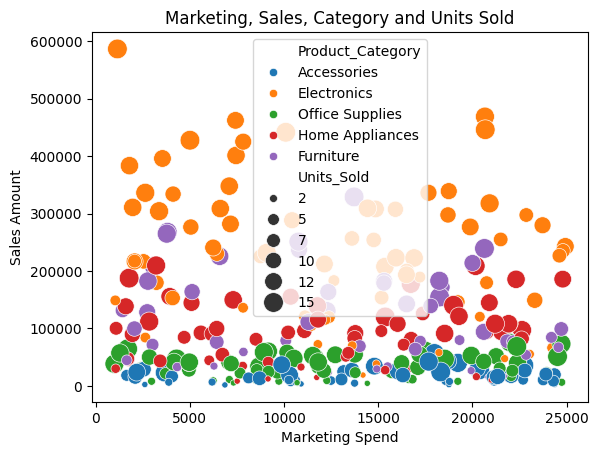

In [ ]:
sns.scatterplot(data=df,x="Marketing_Spend",y="Sales_Amount",hue="Product_Category",size="Units_Sold",sizes=(20, 200))

plt.title("Marketing, Sales, Category and Units Sold")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Amount")
plt.show()

In [38]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

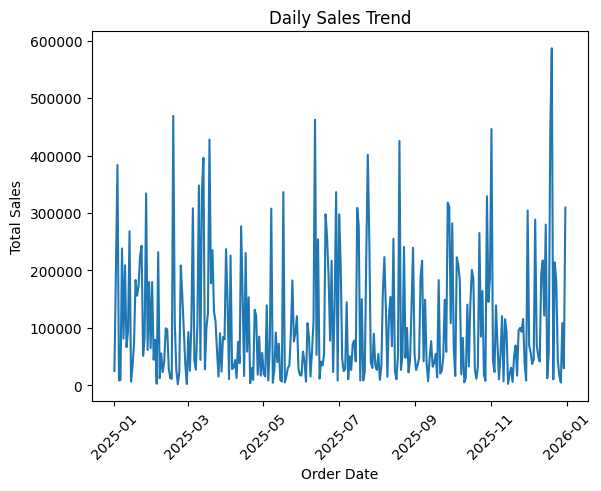

In [39]:
daily_sales = df.groupby("Order_Date")["Sales_Amount"].sum()
sns.lineplot(x=daily_sales.index,y=daily_sales.values)
plt.title("Daily Sales Trend")
plt.xlabel("Order Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

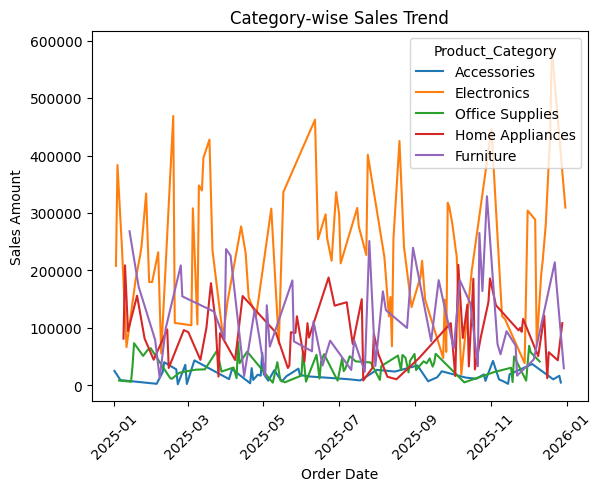

In [40]:
category_sales = df.groupby(["Order_Date", "Product_Category"])["Sales_Amount"].sum().reset_index()

sns.lineplot(data=category_sales,x="Order_Date",y="Sales_Amount",hue="Product_Category")
plt.title("Category-wise Sales Trend")
plt.xlabel("Order Date")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.show()

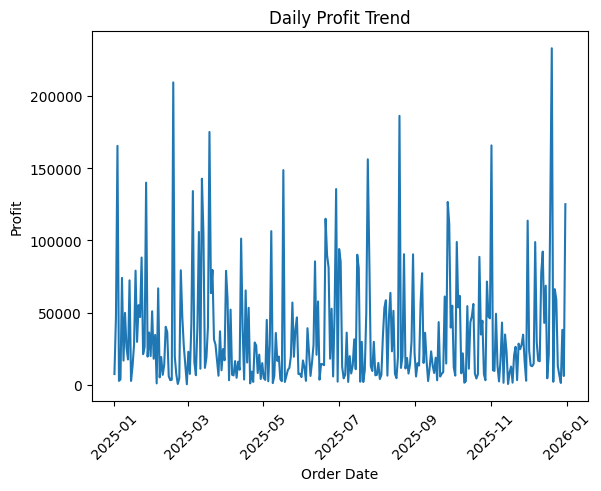

In [41]:
daily_profit = df.groupby("Order_Date")["Profit"].sum()
sns.lineplot(x=daily_profit.index,y=daily_profit.values)

plt.title("Daily Profit Trend")
plt.xlabel("Order Date")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

In [42]:
daily_data = df.groupby("Order_Date").agg(Sales=("Sales_Amount", "sum"),Profit=("Profit", "sum"))

average_sales = daily_data["Sales"].mean()
average_profit = daily_data["Profit"].mean()

high_sales_low_profit = daily_data[(daily_data["Sales"] > average_sales) &(daily_data["Profit"] < average_profit)]

print("Periods with high sales but low profit:")
print(high_sales_low_profit)

Periods with high sales but low profit:
                             Sales    Profit
Order_Date                                  
2025-01-19 06:15:39.130  155817.98  29737.37
2025-02-18 16:41:44.348  108418.25  19737.31
2025-03-22 08:20:52.174  128198.54  31445.83
2025-03-23 13:33:54.783  111943.92  27904.89
2025-04-24 05:13:02.609  131368.94  29322.82
2025-04-25 10:26:05.217  120984.47  27242.83
2025-06-10 16:41:44.348  111141.14  27629.71
2025-07-19 15:39:07.826  149719.91  29794.78
2025-08-05 16:41:44.348  163439.71  33417.64
2025-08-28 19:49:33.913  136002.55  30179.90
2025-11-12 07:18:15.652  114978.37  34825.93
2025-11-26 21:54:46.957  115433.31  34724.80
